In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats

# laduje dane
df = pd.read_excel('WorkPlaceSatisfactionSurveyData.xlsx')

# oddzielam moje kolumny od reszty
SzymonSatVariable = ['sat_management', 'sat_salary', 'sat_workingEnvironment']
my_variables = ['gender', 'age'] + SzymonSatVariable

# tworze nowy daraframe z moimi danymi
dataSzymon = df[my_variables].copy()

# oddzielam plec zeby latwiej sie czytalo
dataSzymon['gender_label'] = dataSzymon['gender'].map({1: 'Female', 2: 'Male'})

print("Dataset ready. Shape:", dataSzymon.shape)
display(dataSzymon)

Dataset ready. Shape: (82, 6)


,gender,age,sat_management,sat_salary,sat_workingEnvironment,gender_label
0,1,38,3,3,3,Female
1,1,29,1,1,2,Female
2,1,30,3,1,1,Female
3,1,36,3,3,3,Female
4,1,24,2,1,2,Female
...,...,...,...,...,...,...
77,1,22,4,3,4,Female
78,1,33,1,1,2,Female
79,1,27,3,3,3,Female
80,1,35,3,3,3,Female


,gender,age,sat_management,sat_salary,sat_workingEnvironment
count,82.00,82.00,82.00,82.00,82.00
mean,1.23,37.95,3.06,2.11,3.22
std,0.42,9.77,1.06,1.11,1.15
min,1.00,20.00,1.00,1.00,1.00
25%,1.00,31.00,2.00,1.00,3.00
50%,1.00,37.50,3.00,2.00,3.00
75%,1.00,44.00,4.00,3.00,4.00
max,2.00,61.00,5.00,5.00,5.00


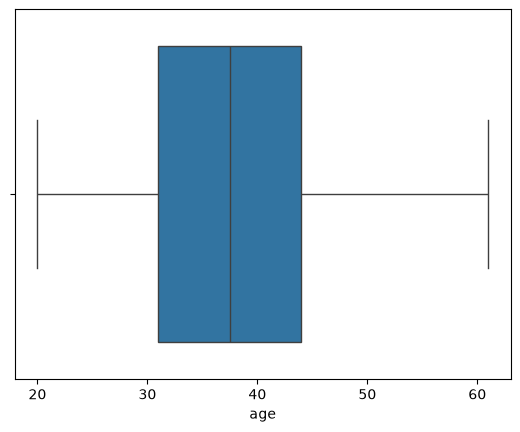

In [2]:
# uzywam z funkcji describe() zeby zobaczyc statystyki opisowe dla moich danych i zaokraglam do 2 miejsc po przecinku
display(dataSzymon.describe().round(2))
# tworze wykresy pudełkowe dla wieku
sns.boxplot(data=dataSzymon, x='age' )
plt.show()

,Count,%
gender_label,,
Female,63,76.8
Male,19,23.2


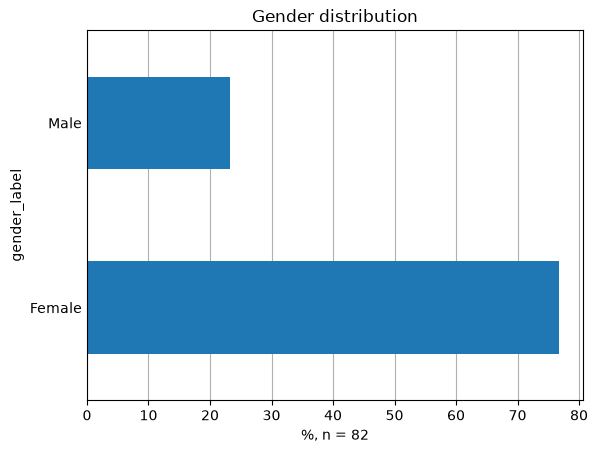

In [3]:
# tworze tabele zliczajaca ilosc osob w kazdej kategorii plec
df1 = dataSzymon['gender_label'].value_counts().to_frame(name='Count')

# licze procentowy udzial kazdej kategorii plec
df1['%'] = (df1['Count'] / df1['Count'].sum() * 100).round(1)

df1['%'].plot.barh(zorder = 2)

plt.title('Gender distribution')

plt.xlabel('%, n = ' + str(df1['Count'].sum()))

plt.grid(axis = 'x')
plt.tick_params(axis = 'y', length = 0)
# tworze wykres slupkowy dla plec

display(df1)

In [4]:
#tworze kategorie wiekowe

bins = [20, 30, 40, 50 , 60, 70]

#rozdzielam wiek na kategorie

df['age_group'] = pd.cut(df['age'], bins = bins)

# tworzę tabelę zliczającą ilość osób w każdej kategorii wiekowej

df3 = pd.crosstab(df['age_group'], 'Count')


#nazywamy tabele kolumny

df3.columns.name = 'Age_Avg'

# i znowu licze procentowy udzial kazdej kategorii wiekowej
n = df3['Count'].sum()
df3['%'] = df3 / n * 100


# licze wszystkie wartosci w tabeli i dodaje je jako nowy rzad na koncu
df3.index = df3.index.astype(str)
df3.loc['Total'] = df3.sum()
df3

#df3['age_group'].hist(bins = bins)
#df3['age'].hist(bins = bins)

#plt.xlabel('Age group')
#plt.ylabel('Count, n=' + str(n))

Age_Avg,Count,%
age_group,,
"(20, 30]",19.0,23.456790
"(30, 40]",35.0,43.209877
"(40, 50]",16.0,19.753086
"(50, 60]",10.0,12.345679
"(60, 70]",1.0,1.234568
Total,81.0,100.000000


<Axes: >

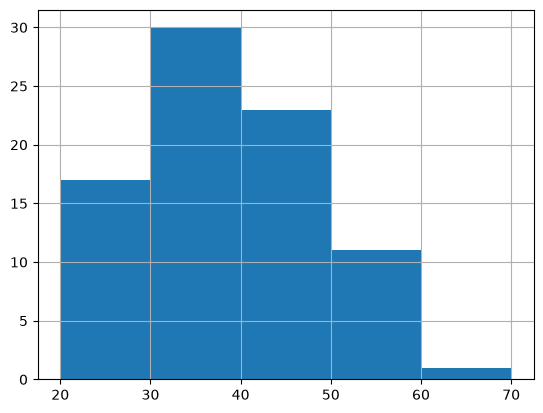

In [5]:
dataSzymon['age'].hist(bins = bins)

In [6]:
genderage = pd.crosstab(df['age_group'], dataSzymon['gender_label'])
display(genderage)

gender_label,Female,Male
age_group,,
"(20, 30]",18,1
"(30, 40]",24,11
"(40, 50]",13,3
"(50, 60]",6,4
"(60, 70]",1,0


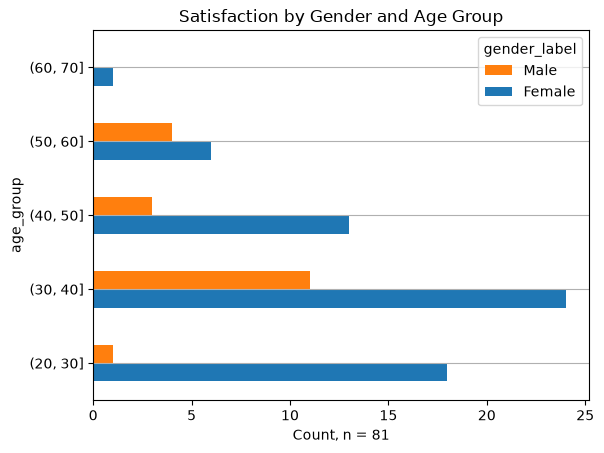

In [7]:
genderage.plot.barh(legend = 'reverse')

#napisuje tytul wykresu

plt.title('Satisfaction by Gender and Age Group')

#liczba osob w kazdej kategorii
plt.xlabel('Count, n = ' + str(genderage.sum().sum()))

plt.grid(axis = 'y')

In [8]:
chi2, p_arvo_chi, dof, expected = stats.chi2_contingency(genderage)
print(f"Chi-square p-arvo: {p_arvo_chi:.4f}")

Chi-square p-arvo: 0.1486


In [9]:
# wyplata kobiet i mezczyzn
miehet_palkka = dataSzymon[dataSzymon['gender_label'] == 'Male']['sat_salary'].dropna()
naiset_palkka = dataSzymon[dataSzymon['gender_label'] == 'Female']['sat_salary'].dropna()
display(miehet_palkka.describe().round(2))
display(naiset_palkka.describe().round(2))
# robie t-test dla porownania srednich wartosci satysfakcji z wyplaty miedzy mezczyznami a kobietami
t_stat, p_arvo_t = stats.ttest_ind(miehet_palkka, naiset_palkka)
print(f"T-test p-arvo (Palkkatyytyväisyys): {p_arvo_t:.4f}")

count    19.00
mean      2.79
std       0.98
min       1.00
25%       2.00
50%       3.00
75%       3.00
max       5.00
Name: sat_salary, dtype: float64

count    63.00
mean      1.90
std       1.07
min       1.00
25%       1.00
50%       1.00
75%       3.00
max       4.00
Name: sat_salary, dtype: float64

T-test p-arvo (Palkkatyytyväisyys): 0.0019


In [10]:
# tworzymy crosstab pomiędzy płcią a satysfakcją z środowiska pracy
crosstab_gender_sat = pd.crosstab(dataSzymon['gender_label'], dataSzymon['sat_workingEnvironment'])

# patrzymy kto jak jest zadowolony z pracy w zależności od płci
display(crosstab_gender_sat)

# robimy test chi-kwadrat dla crosstab_gender_sat
chi2, p_value, dof, expected = stats.chi2_contingency(crosstab_gender_sat)

print(f"\nChi-neliö p-arvo: {p_value:.4f}")

sat_workingEnvironment,1,2,3,4,5
gender_label,,,,,
Female,9,7,27,15,5
Male,0,2,3,8,6



Chi-neliö p-arvo: 0.0092


C:\Users\szuwa\AppData\Local\Temp\ipykernel_45608\1081462477.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.swarmplot(data=dataSzymon, x='gender_label', y='age', palette='Set1', size=6, alpha=0.8)


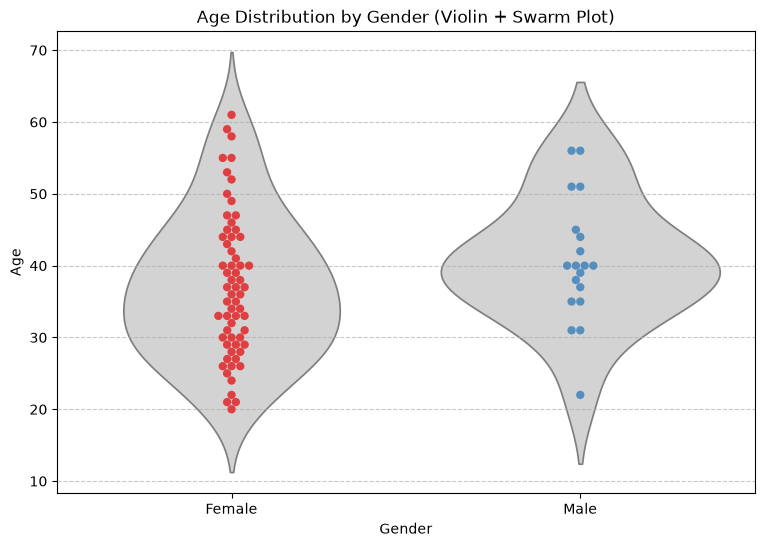

In [11]:
plt.figure(figsize=(9, 6))

# rysuje kształt gęstości jak wykres KDE
sns.violinplot(data=dataSzymon, x='gender_label', y='age', inner=None, color='lightgray')

# zaznaczam dokładne punkty danych na wykresie jak wykres Strip Plot
sns.swarmplot(data=dataSzymon, x='gender_label', y='age', palette='Set1', size=6, alpha=0.8)

plt.title('Age Distribution by Gender (Violin + Swarm Plot)', )
plt.xlabel('Gender')
plt.ylabel('Age')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

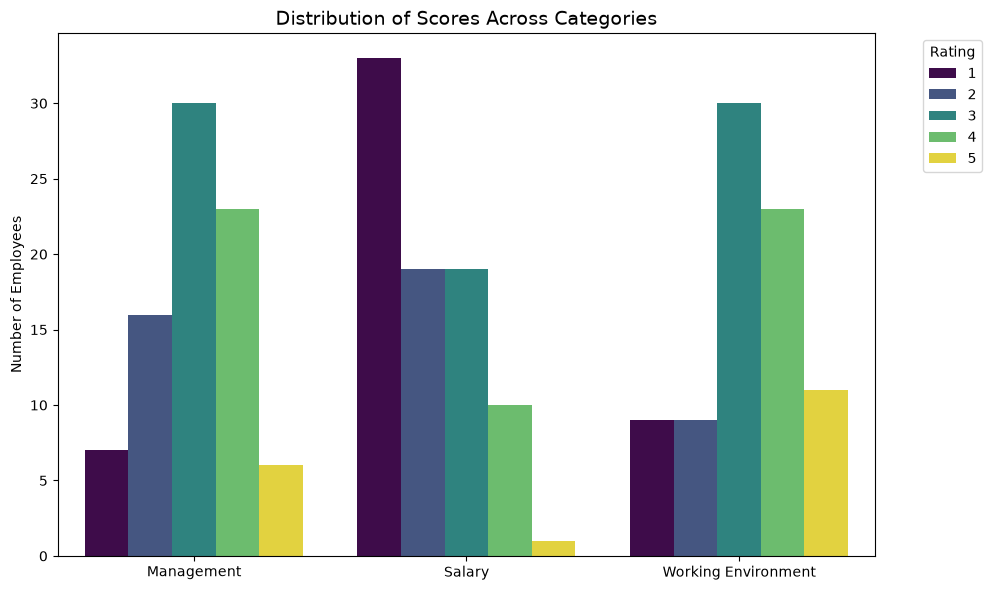

In [16]:
# Definiujemy kolumny z satysfakcją
sat_cols = ['sat_management', 'sat_salary', 'sat_workingEnvironment']

# Przekształcamy dane (angielskie nazwy kolumn)
sat_melted = dataSzymon[sat_cols].melt(var_name='Satisfaction Category', value_name='Score (1-5)')

# Tworzymy wykres
plt.figure(figsize=(10, 6))
sns.countplot(data=sat_melted, x='Satisfaction Category', hue='Score (1-5)', palette='viridis')

# Angielskie tytuły i etykiety
plt.title('Distribution of Scores Across Categories', fontsize=14)
plt.ylabel('Number of Employees')
plt.xlabel('')
plt.xticks(ticks=[0, 1, 2], labels=['Management', 'Salary', 'Working Environment'], rotation=0)
plt.legend(title='Rating', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

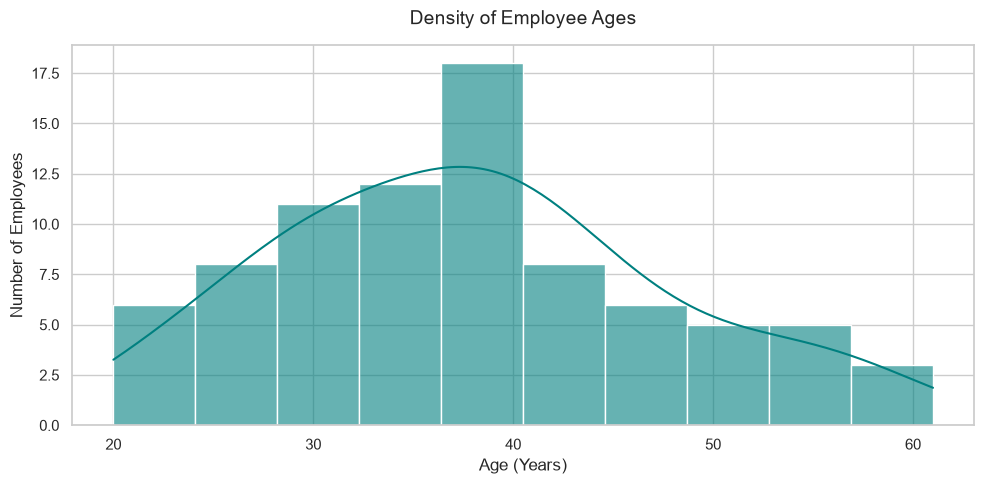

In [ ]:
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# tworzymy histogram wieku z gęstością (KDE) i dostosowujemy kolory oraz przezroczystość
sns.histplot(data=dataSzymon, x='age', bins=10, kde=True, color='teal', alpha=0.6)

plt.title('Density of Employee Ages', fontsize=14, pad=15)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Number of Employees', fontsize=12)
plt.tight_layout()
plt.show()

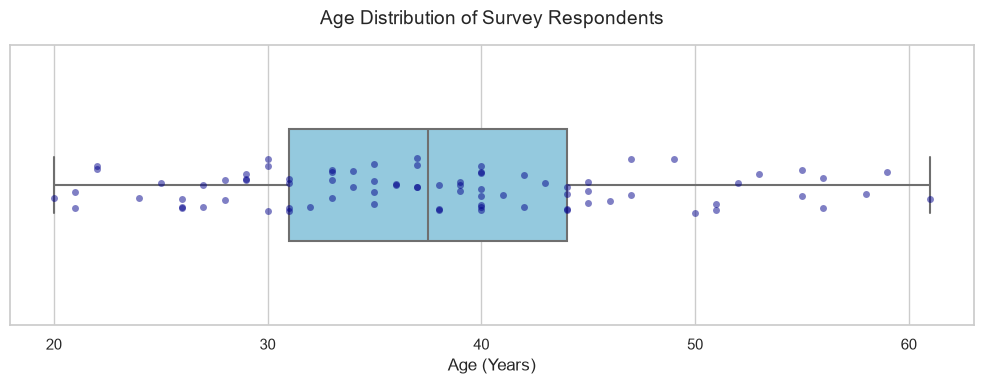

In [ ]:
plt.figure(figsize=(10, 4))
sns.set_theme(style="whitegrid") # dodaje czysty siatkowy tło

# rysuje wykres pudełkowy dla wieku z lepszymi kolorami i szerokością
sns.boxplot(data=dataSzymon, x='age', color='skyblue', width=0.4, linewidth=1.5)

# pokazuje rzeczywiste dane wieku pracowników jako małe kropki
sns.stripplot(data=dataSzymon, x='age', color='darkblue', alpha=0.5, jitter=True, size=5)

plt.title('Age Distribution of Survey Respondents', fontsize=14, pad=15)
plt.xlabel('Age (Years)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# split=True is the magic trick here
sns.violinplot(data=dataSzymon, x='sat_salary', y='gender_label', hue='gender_label', 
               split=True, inner="quart", palette={"Female": "#FF9F1C", "Male": "#2EC4B6"})

plt.title('Salary Satisfaction Density: Men vs. Women', fontsize=16, pad=15)
plt.xlabel('Satisfaction Score (1-5)', fontsize=12)
plt.ylabel('')
plt.xlim(0.5, 5.5) # Keeps the chart tightly wrapped around the 1-5 scores
plt.show()